In [158]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from sklearn.model_selection import cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.impute import SimpleImputer
warnings.filterwarnings("ignore")


In [159]:
df=pd.read_csv("/Users/arjunaji/BIA ARJUN/ML/kfold/titanic.csv")

In [160]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [161]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [162]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [163]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [164]:
age_imputer = SimpleImputer(strategy='median')
df['Age'] = age_imputer.fit_transform(df[['Age']])

In [165]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [166]:
embarked_imputer = SimpleImputer(strategy='most_frequent')
df['Embarked'] = pd.DataFrame(embarked_imputer.fit_transform(df[['Embarked']]))[0]

In [167]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         0
dtype: int64

In [168]:
df= df.drop(["Cabin","PassengerId","Name","Ticket"],axis=1)

In [169]:
df.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S


In [170]:
label_encoder = LabelEncoder()
df["Sex"]= label_encoder.fit_transform(df["Sex"])
df["Embarked"]= label_encoder.fit_transform(df["Embarked"])

In [171]:
df.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,1,22.0,1,0,7.2500,2
1,1,1,0,38.0,1,0,71.2833,0
2,1,3,0,26.0,0,0,7.9250,2
3,1,1,0,35.0,1,0,53.1000,2
4,0,3,1,35.0,0,0,8.0500,2


In [172]:
df.tail()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
886,0,2,1,27.0,0,0,13.00,2
887,1,1,0,19.0,0,0,30.00,2
888,0,3,0,28.0,1,2,23.45,2
889,1,1,1,26.0,0,0,30.00,0
890,0,3,1,32.0,0,0,7.75,1


In [173]:
df.to_csv("titanic_cleaned.csv",index=False)

In [174]:
df["Survived"].value_counts(normalize=True)

Survived
0    0.616162
1    0.383838
Name: proportion, dtype: float64

In [175]:
X= df.drop("Survived",axis=1)
y=df["Survived"]

In [176]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test= train_test_split(X,y,test_size=0.1,random_state=42,stratify=y)

In [177]:
clf = DecisionTreeClassifier(random_state=42)

In [178]:
k=5
cv_scores = cross_val_score(clf, X, y, cv=k)

In [179]:
print(f"Cross-validation scores for each fold(K={k}): {cv_scores}")
print(f"Mean cross-validation score: {cv_scores.mean():.2f}")
print(f"Standard deviation of cross-validation scores: {cv_scores.std():.2f}")

Cross-validation scores for each fold(K=5): [0.74860335 0.79213483 0.80898876 0.73595506 0.81460674]
Mean cross-validation score: 0.78
Standard deviation of cross-validation scores: 0.03


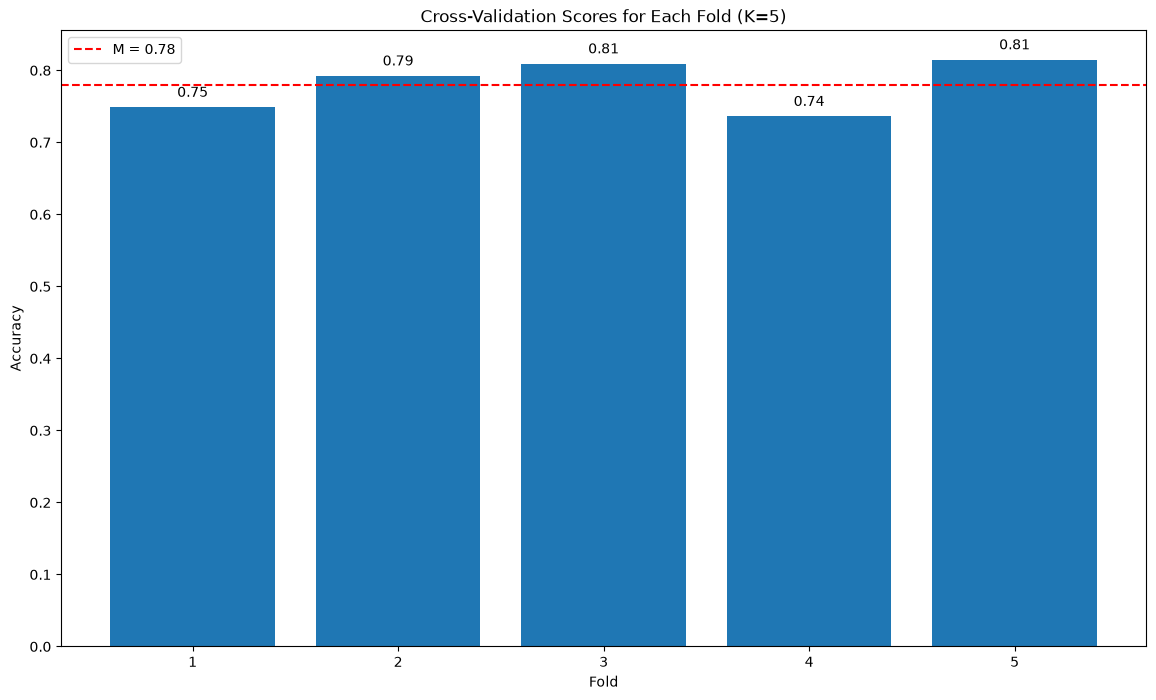

In [180]:
plt.figure(figsize=(14, 8))
plt.bar(range(1, k+1), cv_scores)
for i, score in enumerate(cv_scores):
    plt.text(i + 1, score + 0.01, f"{score:.2f}", ha='center', va='bottom')
# mean accuracy line
plt.axhline(y=cv_scores.mean(), color='r', linestyle='--', label=f'M = {cv_scores.mean():.2f}')
plt.legend()
plt.xlabel('Fold')
plt.ylabel('Accuracy')
plt.title(f'Cross-Validation Scores for Each Fold (K={k})')
plt.xticks(range(1, k+1))
plt.show()

In [181]:
from sklearn.linear_model import LogisticRegression
lr_model = LogisticRegression()
cv_scores_lr = cross_val_score(lr_model, X, y, cv=k)


In [182]:
print(f"Cross-validation scores for each fold(K={k}): {cv_scores_lr}")
print(f"Mean cross-validation score: {cv_scores_lr.mean():.2f}")
print(f"Standard deviation of cross-validation scores: {cv_scores_lr.std():.2f}")

Cross-validation scores for each fold(K=5): [0.7877095  0.78651685 0.78089888 0.76966292 0.82022472]
Mean cross-validation score: 0.79
Standard deviation of cross-validation scores: 0.02


In [183]:
from sklearn.preprocessing import StandardScaler
scalar = StandardScaler()
X_scaled= X.copy()
X_scaled[["Age","Fare"]]= scalar.fit_transform(X_scaled[["Age","Fare"]])


In [184]:
cv_scores_lr = cross_val_score(lr_model, X_scaled, y, cv=10)

In [185]:
print(f"Cross-validation scores for each fold(K={k}): {cv_scores_lr}")
print(f"Mean cross-validation score: {cv_scores_lr.mean():.2f}")
print(f"Standard deviation of cross-validation scores: {cv_scores_lr.std():.2f}")

Cross-validation scores for each fold(K=5): [0.8        0.79775281 0.76404494 0.82022472 0.78651685 0.7752809
 0.78651685 0.78651685 0.80898876 0.84269663]
Mean cross-validation score: 0.80
Standard deviation of cross-validation scores: 0.02


In [186]:
#mannualy adjusstinf the parameters of logistic regression model to see if we can improve the accuracy of the model
lr_model = LogisticRegression(class_weight='balanced', max_iter=200, solver='liblinear')
cv_scores_lr = cross_val_score(lr_model, X_scaled, y, cv=10)
print(f"Cross-validation scores for each fold(K={k}): {cv_scores_lr}")
print(f"Mean cross-validation score: {cv_scores_lr.mean():.2f}")
print(f"Standard deviation of cross-validation scores: {cv_scores_lr.std():.2f}")


Cross-validation scores for each fold(K=5): [0.77777778 0.78651685 0.7752809  0.78651685 0.79775281 0.7752809
 0.76404494 0.76404494 0.80898876 0.79775281]
Mean cross-validation score: 0.78
Standard deviation of cross-validation scores: 0.01


In [187]:
class_weight = df["Survived"].value_counts(normalize=True).to_dict()
lr_model = LogisticRegression(class_weight=class_weight, max_iter=200, solver='liblinear')
cv_scores_lr = cross_val_score(lr_model, X_scaled, y, cv=10)
print(f"Cross-validation scores for each fold(K={k}): {cv_scores_lr}")
print(f"Mean cross-validation score: {cv_scores_lr.mean():.2f}")
print(f"Standard deviation of cross-validation scores: {cv_scores_lr.std():.2f}")


Cross-validation scores for each fold(K=5): [0.76666667 0.78651685 0.7752809  0.85393258 0.85393258 0.78651685
 0.84269663 0.79775281 0.84269663 0.7752809 ]
Mean cross-validation score: 0.81
Standard deviation of cross-validation scores: 0.03


In [188]:
from sklearn.model_selection import GridSearchCV

param_grid = {'penalty': ['l1', 'l2','elasticnet','None'],
               'C': [0.1, 1, 10, 100], 
               'solver': ['liblinear', 'saga'], 
               'max_iter': [100, 200, 300]
            }


In [189]:
grid_search = GridSearchCV(estimator=lr_model, param_grid=param_grid, cv=5,scoring='accuracy')
grid_search.fit(X_scaled, y)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",LogisticRegre...r='liblinear')
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'C': [0.1, 1, ...], 'max_iter': [100, 200, ...], 'penalty': ['l1', 'l2', ...], 'solver': ['liblinear', 'saga']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose v

In [190]:
best_params = grid_search.best_params_
best_score = grid_search.best_score_    
print(f"Best parameters: {best_params}")
print(f"Best cross-validation score: {best_score:.2f}")

Best parameters: {'C': 1, 'max_iter': 100, 'penalty': 'l1', 'solver': 'saga'}
Best cross-validation score: 0.80


In [191]:
final_lr_model = LogisticRegression(**best_params)
final_lr_model.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'l1'
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'saga'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not

In [192]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
def evaluate_model(model,X_test,y_test):
    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test,y_pred)
    print(f"ACCURACY:{accuracy:.2f}")
    classification_rep= classification_report(y_test,y_pred)
    print("CLASSIFICATION REPORT")
    print(classification_rep)
    confusion = confusion_matrix(y_test,y_pred)
    confusion_df = pd.DataFrame(confusion,index=model.classes_,columns=model.classes_)
    print("CONFUSION MATRIX")
    print(confusion_df)
    plt.figure(figsize=(14,7))
    sns.heatmap(confusion_df,annot=True,fmt="d",cmap="Blues")
    plt.title("Confusion Matrix Heatmap")
    plt.ylabel("Actual Values")
    plt.xlabel("Predicted Values")
    plt.show()

ACCURACY:0.64
CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.64      0.95      0.76        55
           1       0.67      0.17      0.27        35

    accuracy                           0.64        90
   macro avg       0.65      0.56      0.52        90
weighted avg       0.65      0.64      0.57        90

CONFUSION MATRIX
    0  1
0  52  3
1  29  6


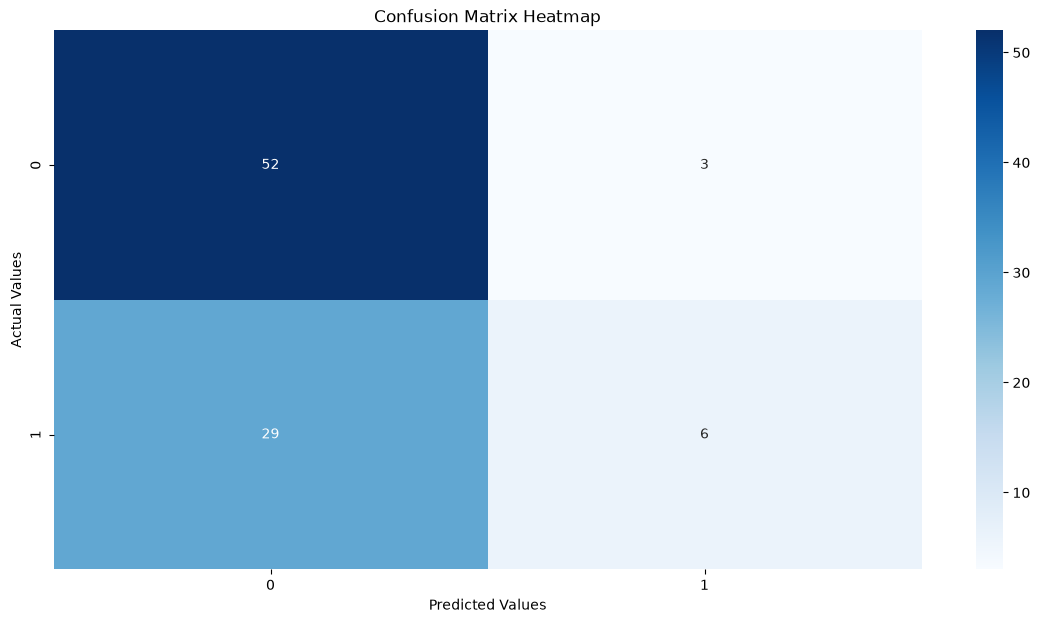

In [193]:
evaluate_model(final_lr_model,X_test,y_test)

In [ ]:
train_accuracy = final_lr_model.score(X_train, y_train)
test_accuracy = final_lr_model.score(X_test, y_test)
print(f"Training Accuracy: {train_accuracy*100:.2f}%")
print(f"Testing Accuracy: {test_accuracy*100:.2f}%")

Training Accuracy: 69.29%
Testing Accuracy: 64.44%
